# Digital rewards research: connect to the expanded SQLite database

Two distinct data layers are stored here: five sourced Hong Kong campaign-rule records and a **simulated**, non-Hong-Kong rewards-app event log. Never combine them as if they were the same users or platform.

## 1. Upload the database

Open this notebook in Google Colab. Click the left-hand **Files** folder, then **Upload**, and select `hk_digital_rewards.sqlite`. The file is about 68 MB, so allow time for upload. A Colab runtime reset removes uploaded files; upload again if needed.

In [ ]:
from pathlib import Path

db_path = Path('/content/hk_digital_rewards.sqlite')
print('Database found:', db_path.exists())
print('Size MB:', round(db_path.stat().st_size / 1024**2, 1) if db_path.exists() else 'upload first')


Database found: True
Size MB: 67.8


**Check:** `Database found: True` and size around 68 MB.

## 2. Open the database and list the tables

`sqlite3.connect` creates a connection to the uploaded file. Listing tables confirms which datasets are present.

In [ ]:
import sqlite3

if not db_path.exists():
    raise FileNotFoundError('Upload hk_digital_rewards.sqlite first.')
connection = sqlite3.connect(db_path)
tables = connection.execute("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name").fetchall()
print(tables)


[('campaigns',), ('dataset_sources',), ('sb_events',), ('sb_offers',), ('sb_users',)]


**Check:** You should see `campaigns`, `dataset_sources`, `sb_events`, `sb_offers`, and `sb_users` (plus SQLite internal tables, if shown). `campaigns` is the Hong Kong public-rule sample; `sb_...` tables are simulated app data.

## 3. Count each research unit

Ask what one row represents before calculating a rate.

In [ ]:
for table in ['campaigns', 'sb_offers', 'sb_users', 'sb_events']:
    n = connection.execute(f'SELECT COUNT(*) FROM {table}').fetchone()[0]
    print(table, n)


campaigns 5
sb_offers 10
sb_users 17000
sb_events 306534


**Expected in this snapshot:** 5 Hong Kong campaign rules; 10 simulated offers; 17,000 simulated users; 306,534 simulated events. Counts are database contents, not study findings.

## 4. Inspect event categories

This first SQL `GROUP BY` summarizes the raw event log. Event counts cannot be read as unique users or funnel rates.

In [ ]:
query = '''
SELECT event_type, COUNT(*) AS event_rows
FROM sb_events
GROUP BY event_type
ORDER BY event_type
'''
for row in connection.execute(query):
    print(row)


('offer completed', 33579)
('offer received', 76277)
('offer viewed', 57725)
('transaction', 138953)


**Expected:** `offer received`, `offer viewed`, `offer completed`, and `transaction`. A person may receive more than one offer; use an offer-instance definition before attempting a funnel.

## 5. Inspect reward business rules

An offer has a type, reward amount, minimum spend (`difficulty_spend`), valid duration, and channels. This is the offer-design layer; it contains no merchant CPA contract.

In [ ]:
query = '''
SELECT offer_type, reward_amount, difficulty_spend, duration_days, channels_json
FROM sb_offers
ORDER BY offer_type, reward_amount
LIMIT 10
'''
for row in connection.execute(query):
    print(row)


('bogo', 5.0, 5.0, 7.0, '["web", "email", "mobile"]')
('bogo', 5.0, 5.0, 5.0, '["web", "email", "mobile", "social"]')
('bogo', 10.0, 10.0, 7.0, '["email", "mobile", "social"]')
('bogo', 10.0, 10.0, 5.0, '["web", "email", "mobile", "social"]')
('discount', 2.0, 10.0, 10.0, '["web", "email", "mobile", "social"]')
('discount', 2.0, 10.0, 7.0, '["web", "email", "mobile"]')
('discount', 3.0, 7.0, 7.0, '["web", "email", "mobile", "social"]')
('discount', 5.0, 20.0, 10.0, '["web", "email"]')
('informational', 0.0, 0.0, 4.0, '["web", "email", "mobile"]')
('informational', 0.0, 0.0, 3.0, '["email", "mobile", "social"]')


## 6. Compare with the Hong Kong rule sample

These are separate cases. Read their source links before drawing conclusions about Hong Kong platform design.

In [ ]:
query = '''
SELECT campaign_id, platform, campaign_name, registration_required, reward_type, source_url
FROM campaigns
ORDER BY campaign_id
'''
for row in connection.execute(query):
    print(row)


('HK001', 'AlipayHK App', 'A. Point Card Welcome Reward', 'Card application in app', 'Stored-value coupon', 'https://www.alipayhk.com/en/a-point-card/')
('HK002', 'Mobile Octopus / Octopus App', 'Mobile Octopus Welcome Reward', 'Yes, promotion webpage', 'Octopus top-up value', 'https://www.octopus.com.hk/en/corporate/media/press-releases/2026/20260316.html')
('HK003', 'Octopus App / Dood Rewards', 'Good Neighbour Rewards', 'Yes', 'Octopus top-up value', 'https://www.octopus.com.hk/tc/corporate/media/press-releases/2026/20260722.html')
('HK004', 'Octopus App / Dood Rewards', 'JoyYou Fest Dood Rewards Welcome Offer', 'Link card and grab designated voucher', 'Cash rebate', 'https://www.octopus.com.hk/en/corporate/media/press-releases/2026/20260825.html')
('HK005', 'Octopus App / Dood Rewards', 'Ride to Fly eStamp and Lucky Draw', 'Yes', 'Miles redemption code plus lucky draw entry', 'https://www.octopus.com.hk/en/corporate/media/press-releases/2026/20260914.html')


## Reflection

1. Which table can show observed receive/view/complete events?
2. Which table describes actual Hong Kong public campaign rules?
3. Why can we not compute Perk Up CPA revenue from these tables?

For the next lesson, we will define a **user × offer receipt** analysis unit and handle repeated offers before calculating any rate.

In [ ]:
connection.close()
print('Connection closed')


In [ ]:
query = """
SELECT person_id, event_type, time_hours, offer_id
FROM sb_events
WHERE person_id = (SELECT person_id FROM sb_events LIMIT 1)
ORDER BY time_hours, event_id
LIMIT 10
"""

for row in connection.execute(query):
    print(row)

('0009655768c64bdeb2e877511632db8f', 'offer received', 168, '5a8bc65990b245e5a138643cd4eb9837')
('0009655768c64bdeb2e877511632db8f', 'offer viewed', 192, '5a8bc65990b245e5a138643cd4eb9837')
('0009655768c64bdeb2e877511632db8f', 'transaction', 228, None)
('0009655768c64bdeb2e877511632db8f', 'offer received', 336, '3f207df678b143eea3cee63160fa8bed')
('0009655768c64bdeb2e877511632db8f', 'offer viewed', 372, '3f207df678b143eea3cee63160fa8bed')
('0009655768c64bdeb2e877511632db8f', 'offer received', 408, 'f19421c1d4aa40978ebb69ca19b0e20d')
('0009655768c64bdeb2e877511632db8f', 'transaction', 414, None)
('0009655768c64bdeb2e877511632db8f', 'offer completed', 414, 'f19421c1d4aa40978ebb69ca19b0e20d')
('0009655768c64bdeb2e877511632db8f', 'offer viewed', 456, 'f19421c1d4aa40978ebb69ca19b0e20d')
('0009655768c64bdeb2e877511632db8f', 'offer received', 504, 'fafdcd668e3743c1bb461111dcafc2a4')


一名用户可以收到多个优惠；交易没有直接关联的优惠 ID；完成事件也可能早于查看事件。计算转化率前，必须先定义如何匹配同一用户的每次优惠。

In [ ]:
query = """
SELECT person_id, offer_id, COUNT(*) AS times_received
FROM sb_events
WHERE event_type = 'offer received'
GROUP BY person_id, offer_id
HAVING COUNT(*) > 1
ORDER BY times_received DESC
LIMIT 5
"""

for row in connection.execute(query):
    print(row)

('23d67a23296a485781e69c109a10a1cf', '5a8bc65990b245e5a138643cd4eb9837', 5)
('2ea50de315514ccaa5079db4c1ecbc0b', 'fafdcd668e3743c1bb461111dcafc2a4', 5)
('43a50d7e5c8547a9aa1ec31291b9fc30', '0b1e1539f2cc45b7b9fa7c272da2e1d7', 5)
('6d2db3aad94648259e539920fc2cf2a6', 'f19421c1d4aa40978ebb69ca19b0e20d', 5)
('eece6a9a7bdd4ea1b0f812f34fc619d6', '5a8bc65990b245e5a138643cd4eb9837', 5)


In [ ]:
sample = connection.execute(query).fetchone()
person_id, offer_id, times_received = sample

for row in connection.execute(
    """
    SELECT event_type, time_hours
    FROM sb_events
    WHERE person_id = ? AND offer_id = ?
    ORDER BY time_hours, event_id
    """,
    (person_id, offer_id)
):
    print(row)

('offer received', 0)
('offer viewed', 84)
('offer received', 168)
('offer viewed', 174)
('offer received', 336)
('offer viewed', 372)
('offer received', 504)
('offer viewed', 504)
('offer received', 576)
('offer viewed', 582)


暂定匹配规则：把一次查看归到同一用户、同一优惠的最近一次、且不晚于查看时间的收到事件；如果已超过该优惠的有效期，就不匹配。再次收到同一优惠时，开启新的一次分析记录。

In [ ]:
query = """
SELECT
    v.time_hours AS viewed_at,
    MAX(r.time_hours) AS matched_received_at
FROM sb_events AS v
JOIN sb_events AS r
  ON v.person_id = r.person_id
 AND v.offer_id = r.offer_id
 AND r.event_type = 'offer received'
 AND (
      r.time_hours < v.time_hours
      OR (r.time_hours = v.time_hours AND r.event_id <= v.event_id)
 )
WHERE v.person_id = ?
  AND v.offer_id = ?
  AND v.event_type = 'offer viewed'
GROUP BY v.event_id
ORDER BY v.time_hours, v.event_id
"""

for row in connection.execute(query, (person_id, offer_id)):
    print(row)

(84, 0)
(174, 168)
(372, 336)
(504, 504)
(582, 576)


### Outcome：查看事件與收到事件的初步配對

針對同一名模擬用戶、同一種優惠，本次查詢把每筆 `offer viewed` 配對到此前最近的一筆 `offer received`。結果為：84→0、174→168、372→336、504→504、582→576（單位：從觀察開始計算的小時）。

這說明同一用戶多次收到相同優惠時，可以先以「每次收到」作為獨立的分析起點。例如，582 小時的查看應初步配對到 576 小時的收到，而不是 0 小時的收到。

**證據邊界：**目前只檢查了一組用戶與優惠；查詢尚未檢查優惠有效期，也沒有配對完成或交易事件。因此這是配對規則的初步檢查，**不是查看率或轉化率結果**。

**查看优惠的时间 → 配对到的收到优惠时间，第 84 小时查看，配对到第 0 小时收到；收到後84小時用戶才查看

In [ ]:
duration_days = connection.execute(
    "SELECT duration_days FROM sb_offers WHERE offer_id = ?",
    (offer_id,)
).fetchone()[0]

duration_hours = duration_days * 24
print("有效期（小時）：", duration_hours)

for viewed_at, received_at in connection.execute(
    query, (person_id, offer_id)
):
    delay = viewed_at - received_at
    print(viewed_at, "→", received_at,
          "| 相隔", delay, "小時",
          "| 有效期內：", delay <= duration_hours)

有效期（小時）： 72.0
84 → 0 | 相隔 84 小時 | 有效期內： False
174 → 168 | 相隔 6 小時 | 有效期內： True
372 → 336 | 相隔 36 小時 | 有效期內： True
504 → 504 | 相隔 0 小時 | 有效期內： True
582 → 576 | 相隔 6 小時 | 有效期內： True


結果正確：這組例子中，84 小時後查看已超過 72 小時有效期；其餘四次查看都在各自配對的收到事件後 72 小時內。這只是一名用戶、一種優惠的檢查結果，不是整體查看率。

In [ ]:
for row in connection.execute("""
    SELECT offer_type, COUNT(*) AS offer_count
    FROM sb_offers
    WHERE reward_amount > 0
    GROUP BY offer_type
    ORDER BY offer_type
"""):
    print(row)

('bogo', 4)
('discount', 4)


所以，原本的 10 种优惠里，有 8 种带奖励；另外 2 种 informational offer 只是传递资讯，奖励数值为 0。这里的 4 是优惠方案的数量，不是 4 名用户，也不是 4 次完成。
这段代码做的事可以读成一句话：
从优惠规则表中，找出奖励数值大于 0 的方案，再按优惠类型数一数。

为什么做这一步？ 你的题目研究 digital campaign rewards。我们先确定哪些方案真正有奖励，后续分析才不会把纯资讯活动混进去。

In [ ]:
row = connection.execute("""
    SELECT offer_type, reward_amount, difficulty_spend, duration_days
    FROM sb_offers
    WHERE offer_type = 'discount'
    LIMIT 1
""").fetchone()

print(row)

('discount', 5.0, 20.0, 10.0)


用户在 10 天有效期内达到 20 的消费门槛，完成后可获得数值为 5 的奖励。

In [ ]:
offer = connection.execute("""
    SELECT offer_id, offer_type, reward_amount,
           difficulty_spend, duration_days
    FROM sb_offers
    WHERE offer_type = 'discount'
      AND reward_amount = 5
      AND difficulty_spend = 20
      AND duration_days = 10
    LIMIT 1
""").fetchone()

print(offer)

('0b1e1539f2cc45b7b9fa7c272da2e1d7', 'discount', 5.0, 20.0, 10.0)


0b1e1539f2cc45b7b9fa7c272da2e1d7 = offer ID

In [ ]:
offer_id = offer[0]

for row in connection.execute(
    """
    SELECT event_type, COUNT(*) AS event_count
    FROM sb_events
    WHERE offer_id = ?
    GROUP BY event_type
    ORDER BY event_type
    """,
    (offer_id,)
):
    print(row)

('offer completed', 3420)
('offer received', 7668)
('offer viewed', 2663)


这项模拟优惠有：
- 收到事件：7,668 条
- 查看事件：2,663 条
- 完成事件：3,420 条

In [ ]:
for row in connection.execute(
    """
    SELECT event_type,
           COUNT(*) AS event_count,
           COUNT(DISTINCT person_id) AS unique_users
    FROM sb_events
    WHERE offer_id = ?
    GROUP BY event_type
    ORDER BY event_type
    """,
    (offer_id,)
):
    print(row)

('offer completed', 3420, 2978)
('offer received', 7668, 6374)
('offer viewed', 2663, 2400)


这次你同时看到了事件次数和人数。以这款模拟数据中的 discount offer 为例：

行为	事件次数	不重复用户数
收到 offer	7,668	6,374
查看 offer	2,663	2,400
完成 offer	3,420	2,978


例如，6,374 人产生了 7,668 次「收到」记录，说明有人不止一次收到同一 offer。现在还不能用 2,978 ÷ 6,374 当作转化率：这两组人数尚未按同一次收到 offer、先后顺序和 10 天有效期配对。完成的人数比查看的人数多，也提醒我们不能直接把这三行当作逐级漏斗。
**下一步只做一件事：**在 Colab 新增一个文字单元格，写下你的分析单位：
同一個人可能多次收到同一個優惠，所以我們要把每次收到都分開看。 然後檢查他有沒有在那次優惠的有效期內查看、完成。這樣才不會把上一次收到的優惠，和這一次完成的行為錯誤地算在一起。

In [ ]:
for row in connection.execute(
    """
    SELECT COUNT(*) AS times_received,
           COUNT(DISTINCT person_id) AS users
    FROM sb_events
    WHERE offer_id = ?
      AND event_type = 'offer received'
    """,
    (offer_id,)
):
    print(row)

(7668, 6374)


In [ ]:
sample_person = connection.execute(
    """
    SELECT person_id
    FROM sb_events
    WHERE offer_id = ?
      AND event_type = 'offer received'
    GROUP BY person_id
    HAVING COUNT(*) > 1
    LIMIT 1
    """,
    (offer_id,)
).fetchone()[0]

for row in connection.execute(
    """
    SELECT event_type, time_hours
    FROM sb_events
    WHERE person_id = ? AND offer_id = ?
    ORDER BY time_hours, event_id
    """,
    (sample_person, offer_id)
):
    print(row)

('offer received', 168)
('offer completed', 210)
('offer viewed', 228)
('offer received', 576)
('offer completed', 666)


這位用戶兩次收到同一優惠，也兩次完成：
- 第一次：第 168 小時收到 → 第 210 小時完成，相隔 42 小時；第 228 小時才出現查看紀錄。
- 第二次：第 576 小時收到 → 第 666 小時完成，相隔 90 小時；這次沒有看到查看紀錄。
所以，這個例子不能硬套「收到 → 查看 → 完成」的固定順序。有完成紀錄，不代表資料中一定有較早的查看紀錄。
下一步只做一件事：在 Colab 新增一個文字儲存格，記下這項觀察：
同一用戶可多次收到並完成同一優惠。在這個樣本中，第一次完成早於查看紀錄，第二次完成前沒有查看紀錄。因此，分析完成情況時不能把「先查看」設為必要條件；查看應另外分析。

In [ ]:
query = """
SELECT
    c.time_hours AS completed_at,
    (
        SELECT r.time_hours
        FROM sb_events AS r
        WHERE r.person_id = c.person_id
          AND r.offer_id = c.offer_id
          AND r.event_type = 'offer received'
          AND (
              r.time_hours < c.time_hours
              OR (r.time_hours = c.time_hours AND r.event_id <= c.event_id)
          )
        ORDER BY r.time_hours DESC, r.event_id DESC
        LIMIT 1
    ) AS received_at
FROM sb_events AS c
WHERE c.person_id = ?
  AND c.offer_id = ?
  AND c.event_type = 'offer completed'
ORDER BY c.time_hours, c.event_id
"""

for completed_at, received_at in connection.execute(
    query, (sample_person, offer_id)
):
    print("完成：", completed_at, "收到：", received_at)

完成： 210 收到： 168
完成： 666 收到： 576


For this user, the first offer was completed 42 hours after they received it. They received the same offer again later and completed it 90 hours after that second time.

In [ ]:
valid_hours = 10 * 24

for completed_at, received_at in connection.execute(
    query, (sample_person, offer_id)
):
    hours_taken = completed_at - received_at
    print(hours_taken, "hours; within 10 days:", hours_taken <= valid_hours)

42 hours; within 10 days: True
90 hours; within 10 days: True


這位用戶兩次收到同一優惠後，分別在 42 小時和 90 小時完成；兩次都早於 10 天（240 小時）的期限。

In [ ]:
check_query = """
WITH matched AS (
    SELECT
        c.event_id,
        c.time_hours AS completed_at,
        MAX(r.time_hours) AS received_at
    FROM sb_events AS c
    LEFT JOIN sb_events AS r
      ON r.person_id = c.person_id
     AND r.offer_id = c.offer_id
     AND r.event_type = 'offer received'
     AND (
         r.time_hours < c.time_hours
         OR (r.time_hours = c.time_hours AND r.event_id <= c.event_id)
     )
    WHERE c.offer_id = ?
      AND c.event_type = 'offer completed'
    GROUP BY c.event_id, c.time_hours
)
SELECT
    COUNT(*) AS all_completions,
    SUM(received_at IS NULL) AS no_earlier_receipt,
    SUM(received_at IS NOT NULL
        AND completed_at - received_at > 240) AS after_10_days,
    SUM(received_at IS NOT NULL
        AND completed_at - received_at BETWEEN 0 AND 240) AS within_10_days
FROM matched
"""

print(connection.execute(check_query, (offer_id,)).fetchone())

(3420, 0, 0, 3420)


這四個數字表示：在這個模擬資料集中，這款 discount offer 有 3,420 筆完成事件；每一筆都能找到該用戶較早收到同一優惠的紀錄，而且都落在最近一次收到後的 10 天內。沒有找不到較早收到紀錄、或超過 10 天的完成事件。
但 3,420 是事件筆數，不是 3,420 位用戶，也不是完成率。這項檢查只證明「時間配對符合我們設定的規則」；尚未證明消費門檻、獎勵資格或真實平台的轉化表現。

In [ ]:
duplicate_query = """
WITH paired AS (
    SELECT
        c.event_id AS completion_id,
        (
            SELECT r.event_id
            FROM sb_events AS r
            WHERE r.person_id = c.person_id
              AND r.offer_id = c.offer_id
              AND r.event_type = 'offer received'
              AND (
                  r.time_hours < c.time_hours
                  OR (r.time_hours = c.time_hours AND r.event_id <= c.event_id)
              )
            ORDER BY r.time_hours DESC, r.event_id DESC
            LIMIT 1
        ) AS receipt_id
    FROM sb_events AS c
    WHERE c.offer_id = ?
      AND c.event_type = 'offer completed'
)
SELECT receipt_id, COUNT(*) AS completions
FROM paired
GROUP BY receipt_id
HAVING COUNT(*) > 1
LIMIT 5
"""

print(connection.execute(duplicate_query, (offer_id,)).fetchall())

[(54616, 2), (55395, 2), (56539, 2), (57028, 2), (61280, 2)]


這個結果發現了重複配對。例如 (54616, 2) 表示：按我們目前「配對到最近一次收到」的規則，收到紀錄 54616 被配到兩筆完成事件。畫面只列出前 5 個例子，因為程式用了 LIMIT 5；不能因此說總共只有 5 個。

In [ ]:
all_duplicates_query = duplicate_query.replace("LIMIT 5", "")
rows = connection.execute(all_duplicates_query, (offer_id,)).fetchall()

print("收到紀錄被配到多筆完成的數量：", len(rows))
print("超出每次收到只計一次的完成筆數：",
      sum(completions - 1 for _, completions in rows))

收到紀錄被配到多筆完成的數量： 106
超出每次收到只計一次的完成筆數： 107


這表示：按目前的配對規則，106 次「收到優惠」各自對應了多筆完成；如果每次收到最多只計一次完成，就有 107 筆額外的完成事件需要去重。它們不一定是錯誤資料，只是不應在「有多少次收到最終帶來完成」這個指標中重複計算。
因此，符合時間條件且去重後的「收到」次數是 3,420 − 107 = 3,313。現在可以進入 Analysis（分析），先算第一個指標。

In [ ]:
completed_receipts = 3420 - 107
all_receipts = 7668

print("有完成的收到次數：", completed_receipts)
print("收到後完成比例：", round(completed_receipts / all_receipts * 100, 1), "%")

有完成的收到次數： 3313
收到後完成比例： 43.2 %


**43.2% 的意思是：**在這份模擬資料中，每 100 次收到這款優惠，約有 43 次能按我們的「最近一次收到、10 天內完成、每次收到只計一次」規則，配到完成紀錄。分母是 7,668 次收到，不是 6,374 位用戶；這也不是 Perk Up 的實際轉化率。

In [ ]:
view_query = """
WITH paired_views AS (
    SELECT
        v.event_id AS view_id,
        (
            SELECT r.event_id
            FROM sb_events AS r
            WHERE r.person_id = v.person_id
              AND r.offer_id = v.offer_id
              AND r.event_type = 'offer received'
              AND (
                  r.time_hours < v.time_hours
                  OR (r.time_hours = v.time_hours AND r.event_id <= v.event_id)
              )
              AND v.time_hours - r.time_hours <= 240
            ORDER BY r.time_hours DESC, r.event_id DESC
            LIMIT 1
        ) AS receipt_id
    FROM sb_events AS v
    WHERE v.offer_id = ?
      AND v.event_type = 'offer viewed'
)
SELECT
    COUNT(*) AS all_views,
    COUNT(DISTINCT receipt_id) AS receipts_with_view,
    SUM(receipt_id IS NULL) AS unmatched_views
FROM paired_views
"""

print(connection.execute(view_query, (offer_id,)).fetchone())

(2663, 2652, 11)


這三個數字表示：
- 2,663：查看事件總數。
- 2,652：去重並按「收到後 10 天內」配對後，有查看行為的「收到」次數。
- 11：無法按這套規則配對的查看事件；目前不能只憑這個結果判定原因。

In [ ]:
viewed_receipts = 2652
all_receipts = 7668

print(round(viewed_receipts / all_receipts * 100, 1), "%")

34.6 %


7,668 次收到優惠中，2,652 次在 10 天內有查看紀錄，所以查看比例是 34.6%。

In [ ]:
overlap_query = """
WITH ordered AS (
    SELECT
        person_id, event_id, event_type, time_hours,
        SUM(CASE WHEN event_type = 'offer received' THEN 1 ELSE 0 END)
            OVER (
                PARTITION BY person_id
                ORDER BY time_hours, event_id
                ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
            ) AS receipt_no
    FROM sb_events
    WHERE offer_id = ?
),
receipts AS (
    SELECT person_id, receipt_no,
           MIN(time_hours) AS received_at
    FROM ordered
    WHERE event_type = 'offer received'
    GROUP BY person_id, receipt_no
),
outcomes AS (
    SELECT
        o.person_id, o.receipt_no,
        MAX(CASE WHEN o.event_type = 'offer viewed'
                  AND o.time_hours - r.received_at BETWEEN 0 AND 240
                 THEN 1 ELSE 0 END) AS viewed,
        MAX(CASE WHEN o.event_type = 'offer completed'
                  AND o.time_hours - r.received_at BETWEEN 0 AND 240
                 THEN 1 ELSE 0 END) AS completed
    FROM ordered AS o
    JOIN receipts AS r
      ON o.person_id = r.person_id
     AND o.receipt_no = r.receipt_no
    GROUP BY o.person_id, o.receipt_no
)
SELECT viewed, completed, COUNT(*) AS receipt_count
FROM outcomes
GROUP BY viewed, completed
ORDER BY viewed, completed
"""

for row in connection.execute(overlap_query, (offer_id,)):
    print(row)

(0, 0, 3240)
(0, 1, 1776)
(1, 0, 1115)
(1, 1, 1537)


In the simulated dataset, 1,776 of the 3,313 offer receipts with a completion had no matched view within the 10-day window. Therefore, viewing and completing should be analysed as separate observed behaviours, rather than treated as a mandatory sequential funnel.

viewed：0 = 沒有配對到查看紀錄；1 = 有配對到查看紀錄。
completed：0 = 沒有配對到完成紀錄；1 = 有配對到完成紀錄。

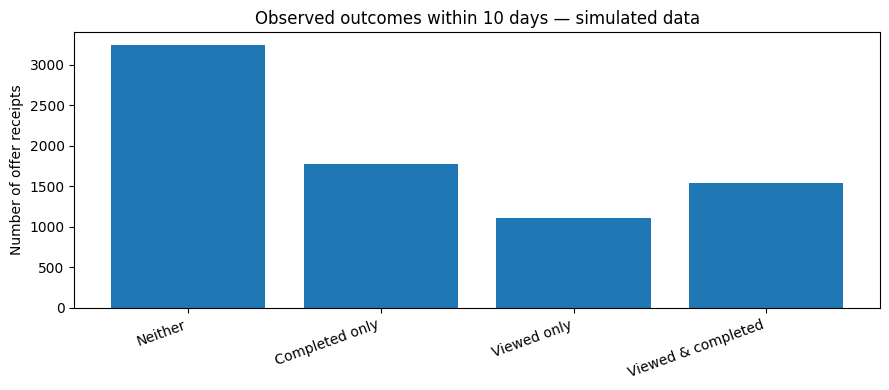

In [ ]:
import matplotlib.pyplot as plt

rows = connection.execute(overlap_query, (offer_id,)).fetchall()

labels = {
    (0, 0): "Neither",
    (0, 1): "Completed only",
    (1, 0): "Viewed only",
    (1, 1): "Viewed & completed"
}

names = [labels[(viewed, completed)] for viewed, completed, count in rows]
counts = [count for viewed, completed, count in rows]

plt.figure(figsize=(9, 4))
plt.bar(names, counts)
plt.ylabel("Number of offer receipts")
plt.title("Observed outcomes within 10 days — simulated data")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

最高的是 Neither（3,240 次）：收到優惠後，10 天內既沒有配對到查看，也沒有配對到完成。另一個值得注意的是 Completed only（1,776 次），它比 **Viewed only（1,115 次）**還多。這再次說明：在這份模擬資料中，不能把「查看」當作完成前的必經步驟。
你現在已經完成了一款優惠的描述性分析與視覺化。下一步只做一件事：找出資料中的 BOGO 優惠，準備比較不同獎勵設計；目前先不要推論哪種設計比較有效。

In [ ]:
for row in connection.execute(
    """
    SELECT offer_id, reward_amount, difficulty_spend, duration_days
    FROM sb_offers
    WHERE offer_type = 'bogo'
    ORDER BY reward_amount, difficulty_spend, duration_days
    """
):
    print(row)

('f19421c1d4aa40978ebb69ca19b0e20d', 5.0, 5.0, 5.0)
('9b98b8c7a33c4b65b9aebfe6a799e6d9', 5.0, 5.0, 7.0)
('4d5c57ea9a6940dd891ad53e9dbe8da0', 10.0, 10.0, 5.0)
('ae264e3637204a6fb9bb56bc8210ddfd', 10.0, 10.0, 7.0)


這四款 BOGO 的獎勵值是 5 或 10，消費門檻是 5 或 10，有效期是 5 或 7 天。
我們先選 獎勵值 5、門檻 5、有效期 7 天那款，與剛才的 discount 優惠做描述性比較。兩者的消費門檻和有效期不同，所以之後即使完成比例不同，也不能說差異是由「BOGO vs discount」造成的。

In [ ]:
bogo_offer_id = "9b98b8c7a33c4b65b9aebfe6a799e6d9"

for row in connection.execute(
    """
    SELECT event_type,
           COUNT(*) AS event_count,
           COUNT(DISTINCT person_id) AS unique_users
    FROM sb_events
    WHERE offer_id = ?
    GROUP BY event_type
    ORDER BY event_type
    """,
    (bogo_offer_id,)
):
    print(row)

('offer completed', 4354, 3784)
('offer received', 7677, 6355)
('offer viewed', 4171, 3658)


這款 BOGO 有 7,677 次收到、4,171 次查看、4,354 次完成。同樣地，事件次數高於不重複用戶數，表示有些用戶對同一款優惠留下了多次紀錄。現在不能直接用 4,354 ÷ 7,677 當完成比例，因為還沒按每次收到優惠配對和去重。
下一步只做一件事：沿用剛才的配對方法，但把有效期改為這款 BOGO 的 7 天＝168 小時。在 Colab 新增一個 Code 儲存格，執行：

In [ ]:
bogo_overlap_query = overlap_query.replace(
    "BETWEEN 0 AND 240",
    "BETWEEN 0 AND 168"
)

for row in connection.execute(bogo_overlap_query, (bogo_offer_id,)):
    print(row)

(0, 0, 1934)
(0, 1, 1615)
(1, 0, 1440)
(1, 1, 2688)


四組合計是 7,677 次收到。其中：
- 有查看：1,440 + 2,688 = 4,128 次
- 有完成：1,615 + 2,688 = 4,303 次
它們是按每次收到優惠、在 7 天內配對並去重的結果，所以與原始的 4,171 次查看、4,354 次完成事件數不同。
下一步只算這款 BOGO 的兩個比例。在 Colab 新增一個 Code 儲存格，執行

In [ ]:
print("收到後查看比例：", round(4128 / 7677 * 100, 1), "%")
print("收到後完成比例：", round(4303 / 7677 * 100, 1), "%")

收到後查看比例： 53.8 %
收到後完成比例： 56.1 %


模擬資料中的優惠	收到後查看	收到後完成
Discount：獎勵值 5、門檻 20、有效期 10 天	34.6%	43.2%
BOGO：獎勵值 5、門檻 5、有效期 7 天	53.8%	56.1%


BOGO 這款的兩個比例都較高，但不能據此說 BOGO 設計比較有效：消費門檻、有效期可能影響結果，接觸渠道也可能不同。
下一步只檢查兩款優惠用了哪些渠道

In [ ]:
for row in connection.execute(
    """
    SELECT offer_type, difficulty_spend, duration_days, channels_json
    FROM sb_offers
    WHERE offer_id IN (?, ?)
    """,
    (offer_id, bogo_offer_id)
):
    print(row)

('discount', 20.0, 10.0, '["web", "email"]')
('bogo', 5.0, 7.0, '["web", "email", "mobile"]')


這又找到一個重要差異：兩款優惠都有 web、email，但 BOGO 額外包含 mobile。因此，剛才較高的查看和完成比例，可能與渠道、消費門檻、有效期或接觸到的用戶有關；不能單獨歸因於 BOGO

In [ ]:
def recipients(offer):
    return {
        row[0] for row in connection.execute(
            """
            SELECT DISTINCT person_id
            FROM sb_events
            WHERE offer_id = ?
              AND event_type = 'offer received'
            """,
            (offer,)
        )
    }

discount_users = recipients(offer_id)
bogo_users = recipients(bogo_offer_id)

print("收到兩款優惠的用戶：", len(discount_users & bogo_users))
print("只收到 discount 的用戶：", len(discount_users - bogo_users))
print("只收到 BOGO 的用戶：", len(bogo_users - discount_users))

收到兩款優惠的用戶： 2099
只收到 discount 的用戶： 4275
只收到 BOGO 的用戶： 4256


In this simulated dataset, the selected BOGO offer had a higher observed view rate (53.8% vs 34.6%) and completion rate (56.1% vs 43.2%) per offer receipt. However, the offers differed in spending threshold, validity period and channels, and only 2,099 users received both. These results describe an association; they do not establish that the BOGO reward design caused higher engagement or completion.

In [ ]:
for row in connection.execute(
    """
    SELECT campaign_id, platform, campaign_name,
           required_action, completion_event,
           reward_type, claim_required
    FROM campaigns
    ORDER BY campaign_id
    """
):
    print(row)

('HK001', 'AlipayHK App', 'A. Point Card Welcome Reward', 'Apply for A. Point Card in AlipayHK App; obtain approval; activate and link card for coupon use', 'Card application approval for automatic coupon placement; eligible card payment for use', 'Stored-value coupon', 'No separate post-approval claim stated in cited section')
('HK002', 'Mobile Octopus / Octopus App', 'Mobile Octopus Welcome Reward', 'Create or transfer Mobile Octopus; register; make one Mobile Octopus transaction of HKD 100 or more', 'Eligible transaction after registration', 'Octopus top-up value', 'Yes, collection step stated')
('HK003', 'Octopus App / Dood Rewards', 'Good Neighbour Rewards', 'Link Octopus to Dood Rewards; register; spend HKD 100 or more in one transaction at a designated merchant', 'Eligible linked-card merchant transaction', 'Octopus top-up value', 'No separate claim described after transaction')
('HK004', 'Octopus App / Dood Rewards', 'JoyYou Fest Dood Rewards Welcome Offer', 'Link JoyYou Card t

這 5 個案例已經顯示：「完成任務」與「取得獎勵」不一定是同一步。 例如 HK002 記載了交易後的領取步驟；HK004 則要求用戶先領券，再完成合資格消費。HK001 和 HK003 的欄位只表示所引來源沒有描述額外領取步驟，不能據此斷言絕對不需要領取。

In [ ]:
for row in connection.execute(
    """
    SELECT campaign_id, consumer_journey,
           reward_delivery, source_url
    FROM campaigns
    WHERE campaign_id IN ('HK002', 'HK004')
    ORDER BY campaign_id
    """
):
    print(row)

('HK002', 'Create/transfer Mobile Octopus > register on promotion webpage > transact > wait 7 days > collect reward', 'Ready 7 days after eligible transaction; collect via Octopus App or service station', 'https://www.octopus.com.hk/en/corporate/media/press-releases/2026/20260316.html')
('HK004', 'Open app > link JoyYou Card > grab voucher > pay HKD 100+ at merchant > obtain additional reward', 'Press release does not specify exact timing for additional welcome reward', 'https://www.octopus.com.hk/en/corporate/media/press-releases/2026/20260825.html')


這兩個香港案例剛好呈現不同的獎勵步驟順序：
- **HK002：**先登記、完成合資格交易，獎勵在交易後 7 天可領取。這是「完成後領取」。Octopus 官方公告
- HK004 的額外 Dood Rewards 迎新獎勵：先連結卡並領取指定優惠券，再完成合資格消費。這是「消費前先領券」；公告沒有說明這筆額外獎勵確切何時發放。Octopus 官方公告

兩種模式：HK002：完成 → 等待 → 領獎；HK004 額外獎勵：領券 → 完成消費 → 發放時間待確認。這會成為你研究「獎勵步驟放在用戶旅程哪個位置」的第一個香港市場對照。

In [ ]:
for row in connection.execute(
    """
    SELECT campaign_id, consumer_journey,
           claim_required, reward_delivery, source_url
    FROM campaigns
    WHERE campaign_id IN ('HK001', 'HK003', 'HK005')
    ORDER BY campaign_id
    """
):
    print(row)

('HK001', 'Open AlipayHK App > apply for card > bank approval > coupon appears in Rewards > activate/link/select card > eligible payment', 'No separate post-approval claim stated in cited section', 'Automatically placed on AlipayHK Rewards page upon approval; applied for eligible payments', 'https://www.alipayhk.com/en/a-point-card/')
('HK003', 'Open Octopus App > link card to Dood Rewards > register > pay at designated merchant > receive top-up reward', 'No separate claim described after transaction', 'Instant reward per press release', 'https://www.octopus.com.hk/tc/corporate/media/press-releases/2026/20260722.html')
('HK005', 'Open Octopus App > link card > register > take eligible trips > accrue stamps > reach 10 stamps > receive code entitlement and draw entry', 'Registration required; downstream code claim method unclear', 'Redemption code entitlement described; exact code delivery UI not confirmed from press release', 'https://www.octopus.com.hk/en/corporate/media/press-releases

案例	獎勵步驟模式	仍需保留的界限
HK001	批卡後優惠券自動放入 Rewards 頁；使用時仍須符合付款條件	自動放入不等於已使用
HK002	合資格交易 → 等待 7 天 → 用戶領取	完成交易不等於已領取
HK003	先連結及登記 → 合資格消費 → 即時獲獎	以公告描述的即時獎勵為準
HK004	先領指定券 → 合資格消費 → 額外獎勵	額外獎勵的確切發放時間未說明
HK005	登記 → 累積 10 個 eStamps → 取得換領碼及抽獎資格	換領碼如何送達、如何使用仍需查證

In [ ]:
for row in connection.execute(
    """
    SELECT campaign_id,
           observed_user_events_available,
           merchant_payout_rule,
           reward_cost_bearer
    FROM campaigns
    ORDER BY campaign_id
    """
):
    print(row)

('HK001', 'No', 'Not publicly disclosed', 'Not publicly disclosed')
('HK002', 'No', 'Not publicly disclosed', 'Not publicly disclosed')
('HK003', 'No', 'Not publicly disclosed', 'Not publicly disclosed')
('HK004', 'No', 'Not publicly disclosed', 'Not publicly disclosed')
('HK005', 'No', 'Not publicly disclosed', 'Not publicly disclosed')


How do Hong Kong digital platforms structure reward eligibility, claiming and delivery across the consumer journey, and what event data would be needed to measure these steps?

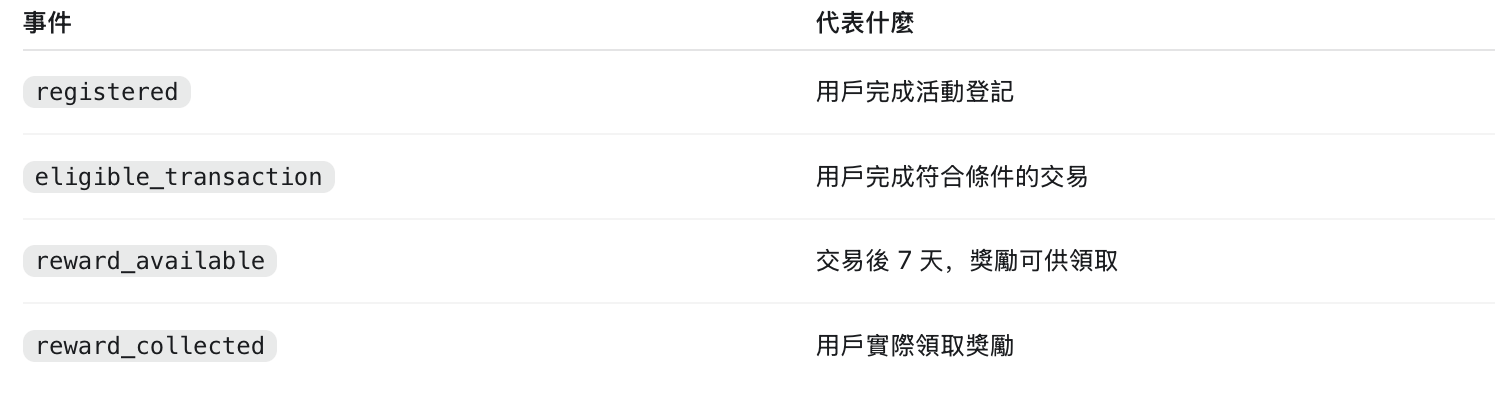